# LlamaHub & LangGraph


## 1. LlamaHub

In [1]:
!pip install -q llama-index llama-index-llms-google-genai llama-index-embeddings-google-genai nest_asyncio
import nest_asyncio
nest_asyncio.apply()

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-google-genai 4.5.0 requires google-genai>=3.2.0, but you have google-genai 2.34.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
from google.colab import userdata
from llama_index.llms.google_genai import GoogleGenAI

llm = GoogleGenAI(
    model="gemini-3.1-flash-lite",
    api_key=userdata.get("GEMINI_API_KEY"),
    temperature=0.7,
    max_tokens=1024,
)

response = llm.complete("Hello, how are you?")
print(response)

I'm doing great, thank you for asking! How are you doing today? Is there anything I can help you with?


In [3]:
from llama_index.embeddings.google_genai import GoogleGenAIEmbedding

embed_model = GoogleGenAIEmbedding(
    model_name="gemini-embedding-001",
    api_key=userdata.get("GEMINI_API_KEY"),
)

print(len(embed_model.get_text_embedding("Hello, how are you?")))

3072


Para empezar, instalamos los componentes necesarios para utilizar Llama y a crear los embeddings que se van a usar.

In [4]:
import os
from llama_index.core import SimpleDirectoryReader

os.makedirs("data", exist_ok=True)
with open("data/alfred_notes.txt", "w") as f:
    f.write("Alfred is the butler of Wayne Manor. He prepares the guest list, the menu, and the music for every party. "
            "The best catering service in Gotham City is Gotham Catering Co.")

reader = SimpleDirectoryReader(input_dir="data")
documents = reader.load_data()
print(len(documents), "document(s) loaded")

1 document(s) loaded


Aquí creamos en el entorno de Colab una carpeta llamada "data" para emular la carga de documentos que se le puede hacer a Llama con SimpleDirectoryReader. De esta forma, podemos explicitar a cuáles documentos va a tener acceso el agente para informar sus respuestas.

In [5]:
from llama_index.core import Document
from llama_index.core.node_parser import SentenceSplitter
from llama_index.core.ingestion import IngestionPipeline
from llama_index.embeddings.google_genai import GoogleGenAIEmbedding

embed_model = GoogleGenAIEmbedding(
    model_name="gemini-embedding-001",
    api_key=userdata.get("GEMINI_API_KEY"),
)

pipeline = IngestionPipeline(
    transformations=[
        SentenceSplitter(chunk_overlap=0),
        embed_model,
    ]
)

nodes = await pipeline.arun(documents=[Document.example()])
print(len(nodes), "node(s) created")

1 node(s) created


Luego se pueden dividir los documentos en nodos, que son fragmentos de un documento que se dividen para que el agente los pueda leer de forma más fácil sin perder contexto. Hay dos formar se romper documentos en nodos, SentenceSplitter que rompe los documentos en pedazos más manejables y HuggingFaceEmbedding que convierte estos pedazos en vectores numéricos.

In [6]:
!pip install -q llama-index-vector-stores-chroma

In [7]:
import chromadb
from llama_index.vector_stores.chroma import ChromaVectorStore

db = chromadb.PersistentClient(path="./alfred_chroma_db")
chroma_collection = db.get_or_create_collection("alfred")
vector_store = ChromaVectorStore(chroma_collection=chroma_collection)

pipeline = IngestionPipeline(
    transformations=[
        SentenceSplitter(chunk_size=25, chunk_overlap=0),
        embed_model,
    ],
    vector_store=vector_store,
)

nodes = await pipeline.arun(documents=documents + [Document.example()])
print(len(nodes), "node(s) stored")

Metadata length (11) is close to chunk size (25). Resulting chunks are less than 50 tokens. Consider increasing the chunk size or decreasing the size of your metadata to avoid this.
Metadata length (9) is close to chunk size (25). Resulting chunks are less than 50 tokens. Consider increasing the chunk size or decreasing the size of your metadata to avoid this.
23 node(s) stored


In [8]:
from llama_index.core import VectorStoreIndex

index = VectorStoreIndex.from_vector_store(vector_store, embed_model=embed_model)

query_engine = index.as_query_engine(
    llm=llm,
    response_mode="tree_summarize",
)
response = query_engine.query("Who is Alfred and what does he prepare for parties?")
print(response)

Alfred is the individual responsible for preparing the guest list and the menu for parties.


Luego utilizamos Chroma para guardar los nodos que se sacaron de los documentos y guardar un índice con el cúal el agente los podrá consultar con facilidad. También establecemos la forma de los queries que se van a utilizar para consultar los nodos, en este caso siendo con query_engine.

In [9]:
from llama_index.core.evaluation import FaithfulnessEvaluator

evaluator = FaithfulnessEvaluator(llm=llm)
eval_result = evaluator.evaluate_response(response=response)
print("Passing:", eval_result.passing)

Passing: True


Para finalizar, vamos a utilizar FaithfulnessEValuator para determinar si la respuesta que proporciona el agente es apoyada por el contexto.

In [10]:
from llama_index.core.tools import FunctionTool

def get_weather(location: str) -> str:
    """Useful for getting the weather for a given location."""
    print(f"Getting weather for {location}")
    return f"The weather in {location} is sunny"

tool = FunctionTool.from_defaults(
    get_weather,
    name="my_weather_tool",
    description="Useful for getting the weather for a given location.",
)
tool.call("New York")

Getting weather for New York


ToolOutput(blocks=[TextBlock(block_type='text', text='The weather in New York is sunny')], tool_name='my_weather_tool', raw_input={'args': ('New York',), 'kwargs': {}}, raw_output='The weather in New York is sunny', is_error=False)

Ahora vamos a crear las herramientas en Llama. Empezamos viendo la forma en la que se pueden definir y utilizar funciones en python como herramientas utilizando FunctionTool.

In [11]:
import chromadb
from llama_index.core import VectorStoreIndex
from llama_index.core.tools import QueryEngineTool
from llama_index.vector_stores.chroma import ChromaVectorStore

db = chromadb.PersistentClient(path="./alfred_chroma_db")
chroma_collection = db.get_or_create_collection("alfred")
vector_store = ChromaVectorStore(chroma_collection=chroma_collection)

index = VectorStoreIndex.from_vector_store(vector_store, embed_model=embed_model)

query_engine = index.as_query_engine(llm=llm)
tool = QueryEngineTool.from_defaults(
    query_engine,
    name="alfred_knowledge",
    description="Answers questions about Alfred, the butler of Wayne Manor, and his party planning.",
)

print(tool.call("Who is Alfred?"))

Alfred is the butler of Wayne Manor.


Con QueryEngineTool se define una herramienta para que el agente pueda hacer consultas a través de los queries que se establecieron anteriormente.

In [12]:
!pip install -q llama-index-tools-google

In [13]:
from llama_index.tools.google import GmailToolSpec

tool_spec = GmailToolSpec()
tool_spec_list = tool_spec.to_tool_list()

[(tool.metadata.name, tool.metadata.description) for tool in tool_spec_list]

[('load_data',
  "load_data() -> List[llama_index.core.schema.Document]\nLoad emails from the user's account."),
 ('search_messages',
  "search_messages(query: str, max_results: Optional[int] = None)\n\nSearches email messages given a query string and the maximum number\nof results requested by the user\n   Returns: List of relevant message objects up to the maximum number of results.\n\nArgs:\n    query (str): The user's query\n    max_results (Optional[int]): The maximum number of search results\n    to return."),
 ('create_draft',
  "create_draft(to: Optional[List[str]] = None, subject: Optional[str] = None, message: Optional[str] = None) -> str\n\nCreate and insert a draft email.\n   Print the returned draft's message and id.\n   Returns: Draft object, including draft id and message meta data.\n\nArgs:\n    to (Optional[str]): The email addresses to send the message to\n    subject (Optional[str]): The subject for the event\n    message (Optional[str]): The message for the event"),

Para finalizar vemos los ToolSpecs, que son una combinación de herramientas definida para un propósito en particular usualmente definidas por usuarios ecternos. En este caso utilizamos un ToolSpec para que el agente tenga acceso a Gmail.

In [14]:
from llama_index.core.agent.workflow import AgentWorkflow
from llama_index.core.tools import FunctionTool

# type annotations, function names, and docstrings are all included in the parsed schema
def multiply(a: int, b: int) -> int:
    """Multiplies two integers and returns the resulting integer"""
    return a * b

agent = AgentWorkflow.from_tools_or_functions(
    [FunctionTool.from_defaults(multiply)],
    llm=llm,
)

response = await agent.run("What is 2 times 2?")
print(response)

2 times 2 is 4.


Ahora si empezamos a inicializar agentes como tal, como podemos ver en la inicialización, se deben establecer las herramientas que el agente puede usar.

In [15]:
from llama_index.core.memory import Memory

memory = Memory.from_defaults(session_id="bob_session", token_limit=30000)

r1 = await agent.run("My name is Bob.", memory=memory)
print("1:", r1)

r2 = await agent.run("What was my name again?", memory=memory)
print("2:", r2)

1: Hello, Bob! It's nice to meet you. How are you doing today?
2: Your name is Bob.


En este caso para que el agente recuerde, se debe establecer un contexto específico aparte porque de por sí solo no lo crea. Toca definir la memoria explícitamente.

In [16]:
from llama_index.core.tools import QueryEngineTool

query_engine = index.as_query_engine(llm=llm, similarity_top_k=3)

query_engine_tool = QueryEngineTool.from_defaults(
    query_engine=query_engine,
    name="alfred_knowledge",
    description="Answers questions about Alfred, the butler of Wayne Manor, and his party planning.",
    return_direct=False,
)

query_engine_agent = AgentWorkflow.from_tools_or_functions(
    [query_engine_tool],
    llm=llm,
    system_prompt="You are a helpful assistant that has access to a database containing information about Alfred and Wayne Manor.",
)

response = await query_engine_agent.run("Who is Alfred and what does he prepare for parties?")
print(response)

Alfred is the butler of Wayne Manor. When it comes to parties, he is responsible for preparing both the guest list and the menu.


Aquí vemos como podemos utilizar una QueryEngineTool para que el agente pueda acceder a información específicada a través del sistema de procesamiento de documentos con el que hemos estado trabajando.

In [17]:
from llama_index.core.agent.workflow import FunctionAgent, ReActAgent

def add(a: int, b: int) -> int:
    """Add two numbers."""
    return a + b

def subtract(a: int, b: int) -> int:
    """Subtract two numbers."""
    return a - b

# FunctionAgent works for LLMs with a function calling API; ReActAgent works for any LLM.
calculator_agent = ReActAgent(
    name="calculator",
    description="Performs basic arithmetic operations",
    system_prompt="You are a calculator assistant. Use your tools for any math operation.",
    tools=[add, subtract],
    llm=llm,
)

query_agent = ReActAgent(
    name="info_lookup",
    description="Looks up information about Alfred and Wayne Manor",
    system_prompt="Use your tool to query a RAG system to answer information about Alfred and Wayne Manor.",
    tools=[query_engine_tool],
    llm=llm,
)

agent = AgentWorkflow(
    agents=[calculator_agent, query_agent], root_agent="calculator"
)

response = await agent.run(user_msg="Can you add 5 and 3?")
print(response)

response = await agent.run(user_msg="Who is Alfred?")
print(response)

5 plus 3 equals 8.
Alfred is the butler of Wayne Manor.


Aquí vemos como podemos implementar sistemas multiagentes, utilizando un agente central de "calculator" y un agente especializados en las consultas de los documentos guardados.

In [18]:
!pip install -q llama-index-utils-workflow

In [19]:
from llama_index.core.workflow import StartEvent, StopEvent, Workflow, step

class MyWorkflow(Workflow):
    @step
    async def my_step(self, ev: StartEvent) -> StopEvent:
        # do something here
        return StopEvent(result="Hello, world!")

w = MyWorkflow(timeout=10, verbose=False)
result = await w.run()
print(result)


Hello, world!


Para finalizar, vamos a ver la creación de workflows.Se definen como una clase en Python que hereda de la clase "Workflow" base, utilizando el decorador @step en sus funciones y los argumentos especiales "StartEvent" y "StopEvent" para cada iniciar y finalizar el workflow.

In [20]:
from llama_index.core.workflow import Event

class ProcessingEvent(Event):
    intermediate_result: str

class MultiStepWorkflow(Workflow):
    @step
    async def step_one(self, ev: StartEvent) -> ProcessingEvent:
        # Process initial data
        return ProcessingEvent(intermediate_result="Step 1 complete")

    @step
    async def step_two(self, ev: ProcessingEvent) -> StopEvent:
        # Use the intermediate result
        final_result = f"Finished processing: {ev.intermediate_result}"
        return StopEvent(result=final_result)

w = MultiStepWorkflow(timeout=10, verbose=False)
result = await w.run()
print(result)

Finished processing: Step 1 complete


Para ligar múltiples pasos en un MultiStepWorkflow, se deben pasar eventos entre sí hasta llamar el StopEvent final.

In [21]:
import random

class LoopEvent(Event):
    loop_output: str

class MultiStepWorkflow(Workflow):
    @step
    async def step_one(self, ev: StartEvent | LoopEvent) -> ProcessingEvent | LoopEvent:
        if random.randint(0, 1) == 0:
            print("Bad thing happened")
            return LoopEvent(loop_output="Back to step one.")
        else:
            print("Good thing happened")
            return ProcessingEvent(intermediate_result="First step complete.")

    @step
    async def step_two(self, ev: ProcessingEvent) -> StopEvent:
        # Use the intermediate result
        final_result = f"Finished processing: {ev.intermediate_result}"
        return StopEvent(result=final_result)

w = MultiStepWorkflow(verbose=False)
result = await w.run()
print(result)

Bad thing happened
Bad thing happened
Good thing happened
Finished processing: First step complete.


Complejizando las cosas más, vemos como se pueden implementar aspectos como eventos en bucle hasta cumplir ciertas condiciones.

In [22]:
from llama_index.utils.workflow import draw_all_possible_flows

draw_all_possible_flows(w, "flow.html")

flow.html


In [23]:
  import html
  from IPython.display import HTML, display

  src = open("flow.html").read()
  display(HTML(f'<iframe srcdoc="{html.escape(src)}" width="100%" height="600" style="border:0"></iframe>'))

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Aquí vemos como se puede graficar el workflow.

In [24]:
from llama_index.core.workflow import Context
class StateWorkflow(Workflow):
    @step
    async def query(self, ctx: Context, ev: StartEvent) -> StopEvent:
        # store query in the context
        await ctx.store.set("query", "What is the capital of France?")

        # retrieve query from the context
        query = await ctx.store.get("query")

        return StopEvent(result=f"Stored and retrieved: {query}")

w = StateWorkflow(timeout=10)
print(await w.run())

Stored and retrieved: What is the capital of France?


Aquí vemos como se le puede añadir estados a los distintos pasos para poder tener trazabilidad y confirmar el estado de cada uno de los pasos, valga la redundancia. También vemos como guardar elementos del workflow dentro del contexto.

In [25]:
def add(a: int, b: int) -> int:
    """Add two numbers."""
    return a + b

def multiply(a: int, b: int) -> int:
    """Multiply two numbers."""
    return a * b

# functions can be passed directly -- name and description are parsed from the signature and docstring
multiply_agent = ReActAgent(
    name="multiply_agent",
    description="Is able to multiply two integers",
    system_prompt="A helpful assistant that can use a tool to multiply numbers.",
    tools=[multiply],
    llm=llm,
)

addition_agent = ReActAgent(
    name="add_agent",
    description="Is able to add two integers",
    system_prompt="A helpful assistant that can use a tool to add numbers.",
    tools=[add],
    llm=llm,
)

workflow = AgentWorkflow(
    agents=[multiply_agent, addition_agent],
    root_agent="multiply_agent",
)

response = await workflow.run(user_msg="Can you add 5 and 3?")
print(response)

5 plus 3 equals 8.


Aquí vemos como podemos implementar un workflow multiagéntico.

In [26]:
async def add(ctx: Context, a: int, b: int) -> int:
    """Add two numbers."""
    cur_state = await ctx.store.get("state")
    cur_state["num_fn_calls"] += 1
    await ctx.store.set("state", cur_state)
    return a + b

async def multiply(ctx: Context, a: int, b: int) -> int:
    """Multiply two numbers."""
    cur_state = await ctx.store.get("state")
    cur_state["num_fn_calls"] += 1
    await ctx.store.set("state", cur_state)
    return a * b

multiply_agent = ReActAgent(
    name="multiply_agent",
    description="Is able to multiply two integers",
    system_prompt="A helpful assistant that can use a tool to multiply numbers.",
    tools=[multiply],
    llm=llm,
)

addition_agent = ReActAgent(
    name="add_agent",
    description="Is able to add two integers",
    system_prompt="A helpful assistant that can use a tool to add numbers.",
    tools=[add],
    llm=llm,
)

workflow = AgentWorkflow(
    agents=[multiply_agent, addition_agent],
    root_agent="multiply_agent",
    initial_state={"num_fn_calls": 0},
    state_prompt="Current state: {state}. User message: {msg}",
)

ctx = Context(workflow)
response = await workflow.run(user_msg="Can you add 5 and 3?", ctx=ctx)
print(response)

state = await ctx.store.get("state")
print("Function calls made:", state["num_fn_calls"])

The sum of 5 and 3 is 8.
Function calls made: 1


También vemos como podemos cambiar los estados del workflow al inicializar para tenerlos más en cuenta.

## 2. LangGraph


In [27]:
!pip install -q langgraph

In [28]:
from typing_extensions import TypedDict

class State(TypedDict):
    graph_state: str

LangGraph funciona a través de 3 componentes; nodos, aristas y estados. Los nodos son las distintas acciones que el agente puede tomar, como llamar al modelo de lenguaje o una herramienta. Las aristas son las condiciones para que el agente tome esa acción y el estado se pasa entre nodo y nodo y sirve para guardar el estado actual del flujo para que el agente decida por donde seguir.

In [29]:
def node_1(state):
    print("---Node 1---")
    return {"graph_state": state['graph_state'] + " I am"}

def node_2(state):
    print("---Node 2---")
    return {"graph_state": state['graph_state'] + " happy!"}

def node_3(state):
    print("---Node 3---")
    return {"graph_state": state['graph_state'] + " sad!"}

Aquí vemos la definición de los nodos que reciben estados y terminan determinando estados actualizados con la función del nodo.

In [30]:
import random
from typing import Literal

def decide_mood(state) -> Literal["node_2", "node_3"]:
    # Often, we will use state to decide on the next node to visit
    user_input = state['graph_state']

    # Here, let's just do a 50 / 50 split between nodes 2, 3
    if random.random() < 0.5:
        # 50% of the time, we return Node 2
        return "node_2"

    # 50% of the time, we return Node 3
    return "node_3"

Aquí vemos la definición de las aristas. En este caso la decisión cae bajo el azar, y dependiendo de por cúal arista se vaya van a terminar en un estado distinto. Usualmente esta decisión va a ser influenciada por el estado actual.

In [31]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# Build graph
builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# Logic
builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_mood)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

# Add
graph = builder.compile()

Aquí creamos toda la lógica del grafo en un único objeto; StateGraph.

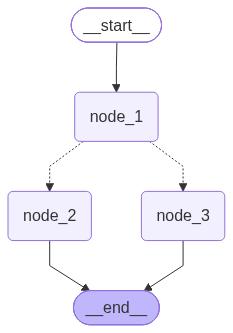

In [32]:
display(Image(graph.get_graph().draw_mermaid_png()))

Dicho objeto se puede visualizar. Aquí podemos ver como la lógica es pasar siempre al nodo 1, de ahí decidir si pasar al nodo 2 o 3 y al final terminar.

In [33]:
graph.invoke({"graph_state": "Hi, this is Lance."})

---Node 1---
---Node 2---


{'graph_state': 'Hi, this is Lance. I am happy!'}

También se puede invocar para ver directamente el camino que se toma en una iteración determinada.

In [34]:
!pip install -q -U langchain-core langchain-google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
llama-index-llms-google-genai 0.11.3 requires google-genai<3,>=1.52.0, but you have google-genai 3.3.0 which is incompatible.
llama-index-embeddings-google-genai 0.6.0 requires google-genai<3,>=1.24.0, but you have google-genai 3.3.0 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.3.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [35]:
from typing import TypedDict, List, Dict, Any, Optional
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage

model = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    google_api_key=userdata.get("GEMINI_API_KEY"),
    temperature=0,
    max_tokens=2048,
)

def text_of(response) -> str:
    content = response.content
    if isinstance(content, str):
        return content
    return "".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)

In [36]:

class EmailState(TypedDict):
    # The email being processed
    email: Dict[str, Any]  # Contains subject, sender, body, etc.

    # Category of the email (inquiry, complaint, etc.)
    email_category: Optional[str]

    # Reason why the email was marked as spam
    spam_reason: Optional[str]

    # Analysis and decisions
    is_spam: Optional[bool]

    # Response generation
    email_draft: Optional[str]

    # Processing metadata
    messages: List[Dict[str, Any]]  # Track conversation with LLM for analysis

Ahora vamos a crear nuesto primer LangGraph. Para empezar se define lo que el estado va a ir guardando nodo por nodo para tomar decisiones.

In [37]:
def read_email(state: EmailState):
    """Alfred reads and logs the incoming email"""
    email = state["email"]

    # Here we might do some initial preprocessing
    print(f"Alfred is processing an email from {email['sender']} with subject: {email['subject']}")

    # No state changes needed here
    return {}

def classify_email(state: EmailState):
    """Alfred uses an LLM to determine if the email is spam or legitimate"""
    email = state["email"]

    # Prepare our prompt for the LLM
    prompt = f"""
    As Alfred the butler, analyze this email and determine if it is spam or legitimate.

    Email:
    From: {email['sender']}
    Subject: {email['subject']}
    Body: {email['body']}

    First, determine if this email is spam. If it is spam, explain why.
    If it is legitimate, categorize it (inquiry, complaint, thank you, etc.).
    """

    # Call the LLM
    messages = [HumanMessage(content=prompt)]
    response = model.invoke(messages)
    reply_text = text_of(response)

    # Simple logic to parse the response (in a real app, you'd want more robust parsing)
    response_text = reply_text.lower()
    is_spam = "spam" in response_text and "not spam" not in response_text

    # Extract a reason if it's spam
    spam_reason = None
    if is_spam and "reason:" in response_text:
        spam_reason = response_text.split("reason:")[1].strip()

    # Determine category if legitimate
    email_category = None
    if not is_spam:
        categories = ["inquiry", "complaint", "thank you", "request", "information"]
        for category in categories:
            if category in response_text:
                email_category = category
                break

    # Update messages for tracking
    new_messages = state.get("messages", []) + [
        {"role": "user", "content": prompt},
        {"role": "assistant", "content": reply_text},
    ]

    # Return state updates
    return {
        "is_spam": is_spam,
        "spam_reason": spam_reason,
        "email_category": email_category,
        "messages": new_messages,
    }

def handle_spam(state: EmailState):
    """Alfred discards spam email with a note"""
    print(f"Alfred has marked the email as spam. Reason: {state['spam_reason']}")
    print("The email has been moved to the spam folder.")

    # We're done processing this email
    return {}

def draft_response(state: EmailState):
    """Alfred drafts a preliminary response for legitimate emails"""
    email = state["email"]
    category = state["email_category"] or "general"

    # Prepare our prompt for the LLM
    prompt = f"""
    As Alfred the butler, draft a polite preliminary response to this email.

    Email:
    From: {email['sender']}
    Subject: {email['subject']}
    Body: {email['body']}

    This email has been categorized as: {category}

    Draft a brief, professional response that Mr. Hugg can review and personalize before sending.
    """

    # Call the LLM
    messages = [HumanMessage(content=prompt)]
    response = model.invoke(messages)
    reply_text = text_of(response)

    # Update messages for tracking
    new_messages = state.get("messages", []) + [
        {"role": "user", "content": prompt},
        {"role": "assistant", "content": reply_text},
    ]

    # Return state updates
    return {
        "email_draft": reply_text,
        "messages": new_messages,
    }

def notify_mr_hugg(state: EmailState):
    """Alfred notifies Mr. Hugg about the email and presents the draft response"""
    email = state["email"]

    print("\n" + "=" * 50)
    print(f"Sir, you've received an email from {email['sender']}.")
    print(f"Subject: {email['subject']}")
    print(f"Category: {state['email_category']}")
    print("\nI've prepared a draft response for your review:")
    print("-" * 50)
    print(state["email_draft"])
    print("=" * 50 + "\n")

    # We're done processing this email
    return {}

Luego creamos los nodos que, como podemos ver, pueden entenderse como acciones. En este caso para un workflow de organización de correos, se definen funciones para leer y organizar correos, lidiar con spam, responder a correos y notificar al usuario sobre un correo en particular.

In [38]:
def route_email(state: EmailState) -> str:
    """Determine the next step based on spam classification"""
    if state["is_spam"]:
        return "spam"
    else:
        return "legitimate"

# Create the graph
email_graph = StateGraph(EmailState)

# Add nodes
email_graph.add_node("read_email", read_email)
email_graph.add_node("classify_email", classify_email)
email_graph.add_node("handle_spam", handle_spam)
email_graph.add_node("draft_response", draft_response)
email_graph.add_node("notify_mr_hugg", notify_mr_hugg)

# Start the edges
email_graph.add_edge(START, "read_email")
email_graph.add_edge("read_email", "classify_email")

# Add conditional branching from classify_email
email_graph.add_conditional_edges(
    "classify_email",
    route_email,
    {
        "spam": "handle_spam",
        "legitimate": "draft_response",
    },
)

# Add the final edges
email_graph.add_edge("handle_spam", END)
email_graph.add_edge("draft_response", "notify_mr_hugg")
email_graph.add_edge("notify_mr_hugg", END)

# Compile the graph
compiled_graph = email_graph.compile()

Luego se define una arista, una forma de decisión en este caso basada en una clasificación de correos sin son spam o no. Naturalmente, si se identifican como spam se va a ir al nodo creado para lidiar con correos spam. Aquí también construimos el objeto del grafo y lo compilamos.

In [39]:
legitimate_email = {
    "sender": "john.smith@example.com",
    "subject": "Question about your services",
    "body": "Dear Mr. Hugg, I was referred to you by a colleague and I'm interested in learning more about your consulting services. Could we schedule a call next week? Best regards, John Smith",
}

spam_email = {
    "sender": "winner@lottery-intl.com",
    "subject": "YOU HAVE WON $5,000,000!!!",
    "body": "CONGRATULATIONS! You have been selected as the winner of our international lottery! To claim your $5,000,000 prize, please send us your bank details and a processing fee of $100.",
}

print("\nProcessing legitimate email...")
legitimate_result = compiled_graph.invoke({
    "email": legitimate_email,
    "is_spam": None,
    "spam_reason": None,
    "email_category": None,
    "email_draft": None,
    "messages": [],
})

print("\nProcessing spam email...")
spam_result = compiled_graph.invoke({
    "email": spam_email,
    "is_spam": None,
    "spam_reason": None,
    "email_category": None,
    "email_draft": None,
    "messages": [],
})


Processing legitimate email...
Alfred is processing an email from john.smith@example.com with subject: Question about your services

Sir, you've received an email from john.smith@example.com.
Subject: Question about your services
Category: inquiry

I've prepared a draft response for your review:
--------------------------------------------------
Subject: Re: Question about your services

Dear Mr. Smith,

Thank you for reaching out. Mr. Hugg has asked me to acknowledge your inquiry and to express his appreciation for the referral.

He would be pleased to discuss your consulting needs. To ensure we find a time that best suits your schedule, could you please suggest a few windows of availability for next week? Once you have provided those, I shall coordinate with Mr. Hugg’s calendar to confirm a suitable time for a call.

I look forward to hearing from you.

Respectfully,

[Your Name/Alfred]
On behalf of Mr. Hugg


Processing spam email...
Alfred is processing an email from winner@lotter

Aquí vemos como el agente  gracias al workflow puede manejar efectivamente distintos tipos de email y procesarlos de la forma en la que lo definimos.

In [40]:
import base64
from typing import Annotated
from langchain_core.messages import AnyMessage, SystemMessage
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

In [41]:
class AgentState(TypedDict):
    # The document provided
    input_file: Optional[str]  # Contains file path (PDF/PNG)
    messages: Annotated[list[AnyMessage], add_messages]

In [42]:
vision_llm = model

def extract_text(img_path: str) -> str:
    """
    Extract text from an image file using a multimodal model.

    Master Wayne often leaves notes with his training regimen or meal plans.
    This allows me to properly analyze the contents.
    """
    all_text = ""
    try:
        # Read image and encode as base64
        with open(img_path, "rb") as image_file:
            image_bytes = image_file.read()

        image_base64 = base64.b64encode(image_bytes).decode("utf-8")

        # Prepare the prompt including the base64 image data
        message = [
            HumanMessage(
                content=[
                    {
                        "type": "text",
                        "text": (
                            "Extract all the text from this image. "
                            "Return only the extracted text, no explanations."
                        ),
                    },
                    {
                        "type": "image_url",
                        "image_url": {
                            "url": f"data:image/png;base64,{image_base64}"
                        },
                    },
                ]
            )
        ]

        # Call the vision-capable model
        response = vision_llm.invoke(message)

        # Append extracted text
        all_text += text_of(response) + "\n\n"

        return all_text.strip()
    except Exception as e:
        # A butler should handle errors gracefully
        error_msg = f"Error extracting text: {str(e)}"
        print(error_msg)
        return ""

def divide(a: int, b: int) -> float:
    """Divide a and b - for Master Wayne's occasional calculations."""
    return a / b

# Equip the butler with tools
tools = [
    divide,
    extract_text,
]

agent_llm = model
llm_with_tools = agent_llm.bind_tools(tools)

In [43]:
def assistant(state: AgentState):
    # System message
    textual_description_of_tool = """
extract_text(img_path: str) -> str:
    Extract text from an image file using a multimodal model.

    Args:
        img_path: A local image file path (strings).

    Returns:
        A single string containing the concatenated text extracted from each image.
divide(a: int, b: int) -> float:
    Divide a and b
"""
    image = state["input_file"]
    sys_msg = SystemMessage(content=f"You are a helpful butler named Alfred that serves Mr. Wayne and Batman. You can analyse documents and run computations with provided tools:\n{textual_description_of_tool} \n You have access to some optional images. Currently the loaded image is: {image}")

    return {
        "messages": [llm_with_tools.invoke([sys_msg] + state["messages"])],
        "input_file": state["input_file"],
    }

Para finalizar, vamos a ver la forma en que podemos involucrar modelos de vision en nuestro workflow. Para empezar definimos el estado y los nodos como tal, con un nodo en particular teniendo la responsabilidad de extraer texto de imágenes.

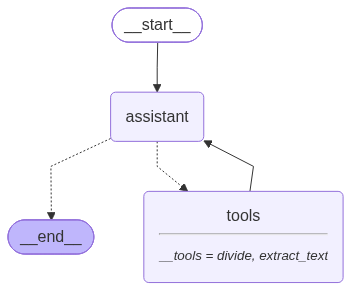

In [44]:
# The graph
builder = StateGraph(AgentState)

# Define nodes: these do the work
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

# Define edges: these determine how the control flow moves
builder.add_edge(START, "assistant")
builder.add_conditional_edges(
    "assistant",
    # If the latest message requires a tool, route to tools
    # Otherwise, provide a direct response
    tools_condition,
)
builder.add_edge("tools", "assistant")
react_graph = builder.compile()

# Show the butler's thought process
display(Image(react_graph.get_graph(xray=True).draw_mermaid_png()))

Ahora definimos el grafo y lo compilamos y podemos ver la lógica. Es un ciclo mientras el agente resuelve la respuesta con ayuda de la herramienta hasta que tenga una respuesta exacta.

In [45]:
messages = [HumanMessage(content="Divide 6790 by 5")]
messages = react_graph.invoke({"messages": messages, "input_file": None})

# Show the messages
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Divide 6790 by 5
================================== Ai Message ==================================

[]
Tool Calls:
  divide (call_2326090588033214357)
 Call ID: call_2326090588033214357
  Args:
    a: 6790
    b: 5
================================= Tool Message =================================
Name: divide

1358.0
================================== Ai Message ==================================

[{'type': 'text', 'text': 'Certainly, sir. 6790 divided by 5 is 1358. Is there anything else you require?', 'extras': {'signature': 'EnMKcQFpFH0TM6YT2cCDeYzNPRGIqjng1ehKfKwe53zZQnYfyLu4uGlRMuVgBi2gwTRLpUW6M/pz8ei1EXxgMtrZ93gVAhR5cbZWBwzEwRBT0j1ZEQFDNc0CL0de2Q8Au8eSNcoy4DHvwFD1AVKw8sQntkzx'}}]


Aquí vemos un ejemplo sencillo del workflow en acción sin involucrar imágenes.

In [46]:
from PIL import Image as PILImage, ImageDraw, ImageFont

note = PILImage.new("RGB", (900, 500), "white")
draw = ImageDraw.Draw(note)
try:
    font = ImageFont.load_default(size=28)
except TypeError:
    font = ImageFont.load_default()

lines = [
    "Training schedule",
    "Mon: push-ups and pull-ups",
    "Wed: sparring",
    "",
    "Dinner menu",
    "Grilled salmon",
    "Roasted vegetables",
    "Brown rice",
    "Green tea",
]
y = 30
for line in lines:
    draw.text((40, y), line, fill="black", font=font)
    y += 45

note.save("Batman_training_and_meals.png")

In [47]:
messages = [HumanMessage(content="According to the note provided by Mr. Wayne in the provided images. What's the list of items I should buy for the dinner menu?")]
messages = react_graph.invoke({"messages": messages, "input_file": "Batman_training_and_meals.png"})

for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

According to the note provided by Mr. Wayne in the provided images. What's the list of items I should buy for the dinner menu?
================================== Ai Message ==================================

[]
Tool Calls:
  extract_text (call_5350327577941100507)
 Call ID: call_5350327577941100507
  Args:
    img_path: Batman_training_and_meals.png
================================= Tool Message =================================
Name: extract_text

Training schedule
Mon: push-ups and pull-ups
Wed: sparring

Dinner menu
Grilled salmon
Roasted vegetables
Brown rice
Green tea
================================== Ai Message ==================================

[{'type': 'text', 'text': 'Certainly, Master Wayne. According to the note you left, the items required for the dinner menu are:\n\n*   Salmon (for grilling)\n*   Assorted vegetables (for roasting)\n*   Brown rice\n*   Green tea\n\nShall I have these deliv

Ahora vemos al modelo en acción cuando está procesando imágenes y vemos que logra correctamente llamar a la herramienta para leer la imagen proporcionada.

NOTA: Las diferencias de código entre este cuaderno y el original de Hugging Face se dieron a problemas de créditos apra utilizar los modelos propuestos. Se utilizó un modelo alterno de Google y el código fue cambiado con ayuda de la IA Claude sólo para este propósito.